# PHM08 turbofan exploration
This notebook uses the bundled run-to-failure training trajectories. The truncated
test trajectories have no released RUL labels and are never labeled using their final cycle.
Sensor numbers follow the repository's 26-column schema; sensor names alone do not
establish a physical failure cause.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.maintenance.cleaner import read_data, Cleaner, inject_mess
from src.data.preprocessing import SENSORS, OP_SETTINGS
df = read_data(ROOT / 'data/train.txt')
display(pd.DataFrame({'observations': [len(df)], 'engines': [df.unit_id.nunique()],
                     'sensors': [len(SENSORS)], 'missing': [int(df.isna().sum().sum())]}))
display(df.describe().T)


,observations,engines,sensors,missing
0,45918,218,21,0


,count,mean,std,min,25%,50%,75%,max
unit_id,45918.0,109.396511,62.866193,1.0000,54.000000,110.0000,164.0000,218.0000
cycle,45918.0,110.307396,68.420545,1.0000,53.000000,106.0000,160.0000,357.0000
op_setting_1,45918.0,24.008881,14.793676,0.0000,10.004500,25.0015,41.9981,42.0080
op_setting_2,45918.0,0.571251,0.310935,0.0000,0.250600,0.7000,0.8400,0.8420
op_setting_3,45918.0,49.172438,32.503659,0.0000,20.000000,40.0000,80.0000,100.0000
sensor_1,45918.0,472.861677,26.460179,445.0000,445.000000,462.5400,491.1900,518.6700
sensor_2,45918.0,579.596770,37.391068,535.6500,549.580000,555.9850,607.3700,644.4300
sensor_3,45918.0,1419.947816,106.286960,1245.4300,1352.910000,1369.1400,1499.6975,1614.6600
sensor_4,45918.0,1205.669194,119.550936,1029.4900,1124.010000,1138.8700,1307.4375,1442.3600
sensor_5,45918.0,8.029878,3.627125,3.9100,3.910000,7.0500,10.5200,14.6200


## Engine lifetimes and operating conditions

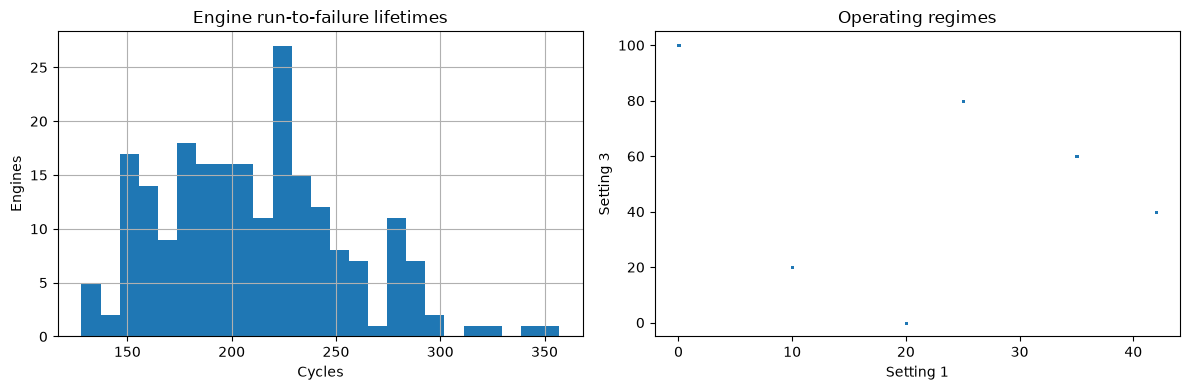

,standard_deviation
sensor_16,0.004722
sensor_10,0.127832
sensor_15,0.751834
sensor_11,3.243475
sensor_5,3.627125
sensor_19,5.378969
sensor_6,5.451857
sensor_21,5.941954
sensor_20,9.903697
sensor_1,26.460179


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.groupby('unit_id').cycle.max().hist(bins=25, ax=axes[0])
axes[0].set(title='Engine run-to-failure lifetimes', xlabel='Cycles', ylabel='Engines')
axes[1].scatter(df.op_setting_1, df.op_setting_3, s=1, alpha=.15)
axes[1].set(title='Operating regimes', xlabel='Setting 1', ylabel='Setting 3')
plt.tight_layout()
plt.show()
display(df[SENSORS].std().sort_values().to_frame('standard_deviation'))


## Sensor distributions and correlations
Operating regimes can confound these associations.

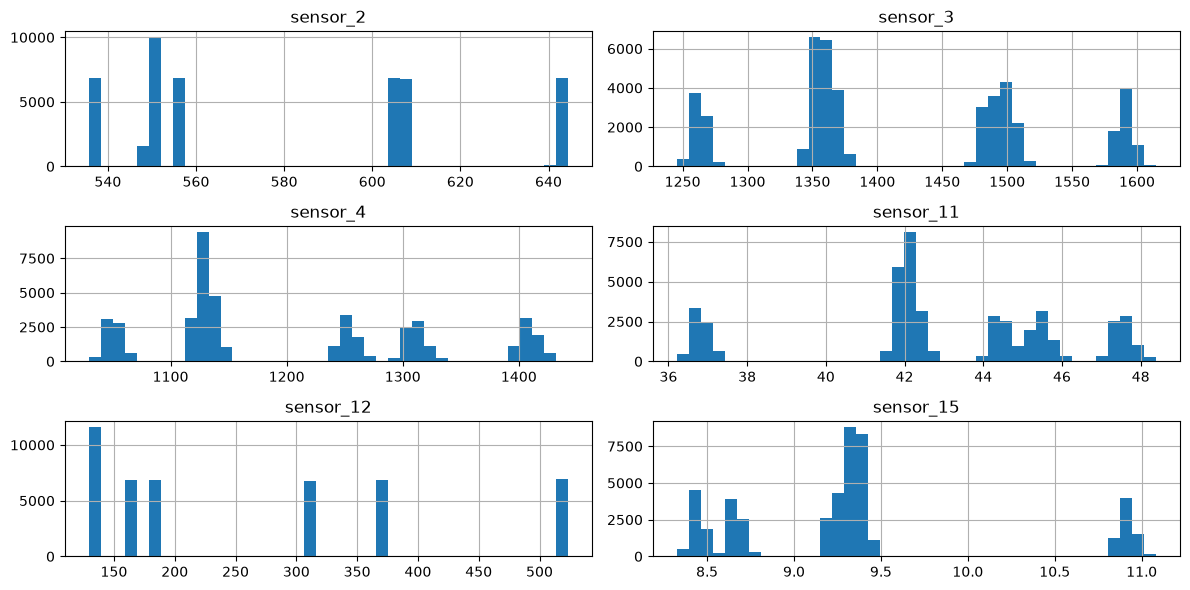

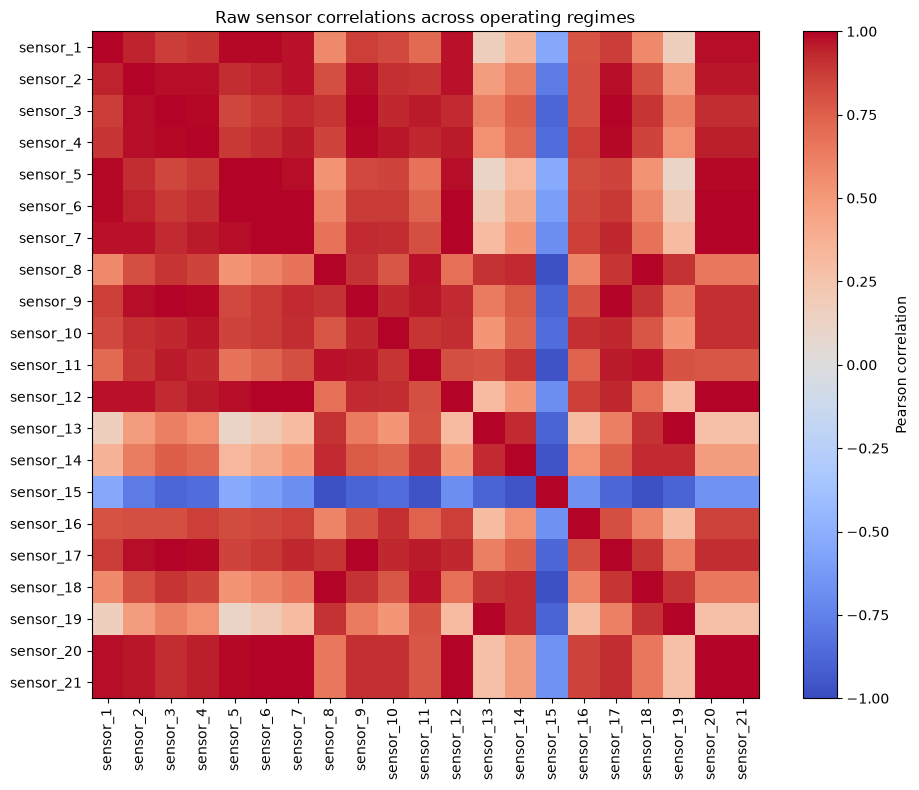

In [3]:
df[['sensor_2','sensor_3','sensor_4','sensor_11','sensor_12','sensor_15']].hist(
    bins=40, figsize=(12, 6))
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(df[SENSORS].corr(), vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(SENSORS)), SENSORS, rotation=90)
ax.set_yticks(range(len(SENSORS)), SENSORS)
fig.colorbar(im, ax=ax, label='Pearson correlation')
ax.set_title('Raw sensor correlations across operating regimes')
plt.tight_layout()
plt.show()


## Degradation patterns
Rolling means use past observations only. Variations also reflect operating conditions.

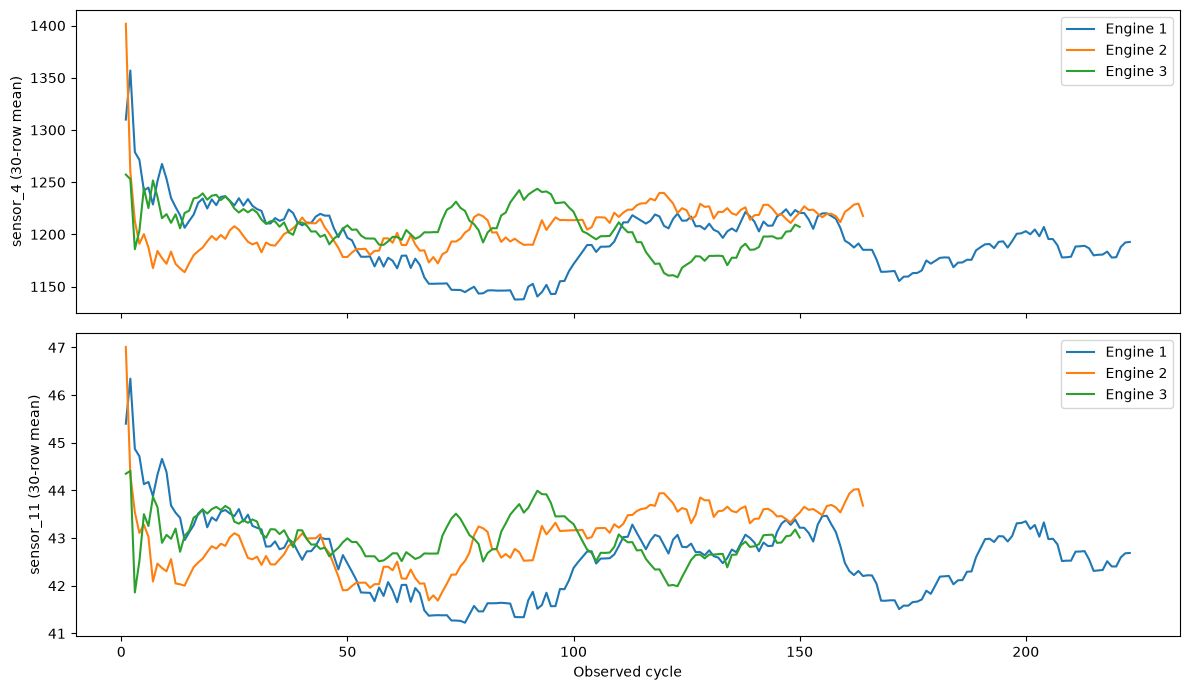

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for uid in [1, 2, 3]:
    g = df[df.unit_id == uid]
    for ax, sensor in zip(axes, ['sensor_4', 'sensor_11']):
        ax.plot(g.cycle, g[sensor].rolling(30, min_periods=1).mean(), label=f'Engine {uid}')
        ax.set_ylabel(sensor + ' (30-row mean)')
for ax in axes:
    ax.legend()
axes[-1].set_xlabel('Observed cycle')
plt.tight_layout()
plt.show()


## Reproducible corruption and causal cleaning

In [5]:
engine_ids = sorted(df.unit_id.unique())
fit_ids = engine_ids[:int(len(engine_ids)*.6)]
cleaner = Cleaner().fit(df[df.unit_id.isin(fit_ids)])
held_out = df[~df.unit_id.isin(fit_ids)]
dirty = inject_mess(held_out, seed=42)
cleaned, quality = cleaner.transform(dirty)
display(pd.Series(quality, name='cleaning_report'))
assert not cleaned.isna().any().any()
assert not cleaned.duplicated(['unit_id', 'cycle']).any()


input_rows            19026.000000
output_rows           18653.000000
duplicates_removed      373.000000
missing_values         8860.000000
outliers_replaced      2243.000000
repair_fraction           0.024802
Name: cleaning_report, dtype: float64

## Modeling decisions
Use engine-disjoint training, validation, and test partitions. Fit cleaning statistics only on
training engines. Build causal window means, standard deviations, and changes, then classify
whether observed end of life is within 30 cycles. Tune the alert threshold only on validation
engines using a configurable false-negative penalty (10 versus 1 by default).
Report precision, recall, F1, ROC-AUC, PR-AUC, confusion matrix, and cost on held-out engines.
The notebook's exploration split is illustrative; the canonical seeded split is saved by the trainer.
